In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from dsp7265 import DSP7265

from pymeasure.instruments.agilent import Agilent8257D

%matplotlib inline

In [2]:
rf_source = Agilent8257D("GPIB::19")
rf_source.enable()

In [58]:
lockin = DSP7265("GPIB::12")

In [61]:
lockin.auto_phase()

In [62]:
lockin.phase

-16.02

In [3]:
rf_source.frequency

16000000000.0

In [5]:
rf_source.write(":FREQ 8e9 Hz;")

In [13]:
int(rf_source.ask(":SOUR:CORR:FLAT:POIN?;"))

1451

In [3]:
rf_source.ask(":SOUR:CORR:STAT?")

'0\n'

In [14]:
rf_source.write(":SOUR:CORR:STAT OFF")

In [11]:
rf_source.write(":SOUR:CORR:STAT ON")

In [117]:
rf_source.write(":SOUR:CORR:FLAT:PRES")

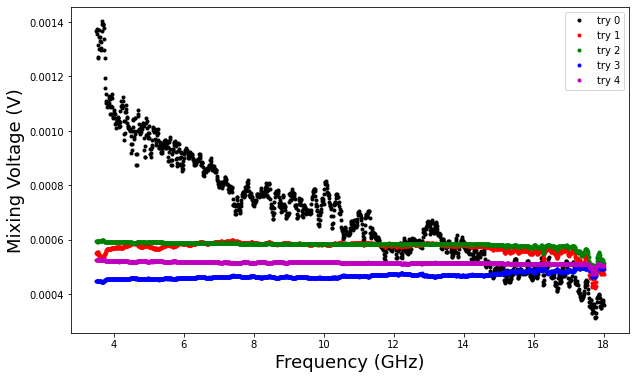

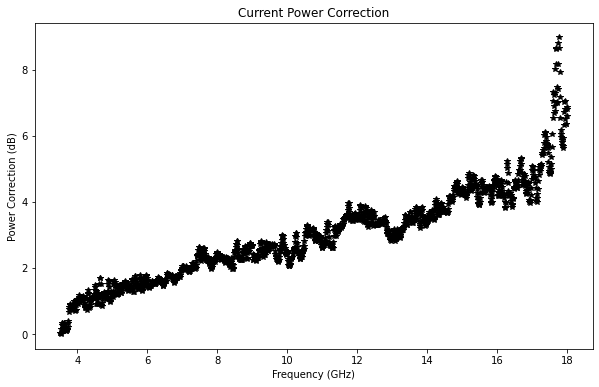

In [5]:
Fref = 10*1e9

datatable0 = pd.read_csv(r"F:\Maciej\Skyrmion_STFMR\23_1_2024\Power_Flatten\2024-01-27\try0.csv",comment='#')
datatable1 = pd.read_csv(r"F:\Maciej\Skyrmion_STFMR\23_1_2024\Power_Flatten\2024-01-27\try1.csv",comment='#')
datatable2 = pd.read_csv(r"F:\Maciej\Skyrmion_STFMR\23_1_2024\Power_Flatten\2024-01-27\try2.csv",comment='#')
datatable3 = pd.read_csv(r"F:\Maciej\Skyrmion_STFMR\23_1_2024\Power_Flatten\2024-01-27\try3.csv",comment='#')
datatable4 = pd.read_csv(r"F:\Maciej\Skyrmion_STFMR\23_1_2024\Power_Flatten\2024-01-27\try4.csv",comment='#')

arrX0 = datatable0.X.to_numpy()
arrX1 = datatable1.X.to_numpy()
arrX2 = datatable2.X.to_numpy()
arrX3 = datatable3.X.to_numpy()
arrX4 = datatable4.X.to_numpy()
# arrX5 = datatable5.X.to_numpy()
# arrX6 = datatable6.X.to_numpy()
# arrX7 = datatable7.X.to_numpy()
# arrX8 = datatable8.X.to_numpy()
# arrX9 = datatable9.X.to_numpy()
# arrX10 = datatable10.X.to_numpy()
# arrX11 = datatable11.X.to_numpy()
# arrX12 = datatable12.X.to_numpy()
arrF = datatable0.rf_freq.to_numpy()

Indexref = np.where(arrF == Fref)
Vref = arrX0[Indexref]
arrP0 = -10*np.log10(arrX0 / Vref)
arrP1 = -10*np.log10(arrX1 / Vref)
arrP2 = -10*np.log10(arrX2 / Vref)
arrP3 = -10*np.log10(arrX3 / Vref)
arrP4 = -10*np.log10(arrX4 / Vref)
# arrP5 = -10*np.log10(arrX5 / Vref)
# arrP6 = -10*np.log10(arrX6 / Vref0)
# arrP7 = -10*np.log10(arrX7 / Vref0)
# arrP9 = -10*np.log10(arrX9 / Vref0)
# arrP10 = -10*np.log10(arrX10 / Vref0)
# arrP11 = -10*np.log10(arrX11 / Vref0)
# arrP12 = -10*np.log10(arrX12 / Vref0)
arrP = arrP0 + arrP1 + arrP2 + arrP3 + arrP4

plt.figure(figsize=(10, 6))
plt.plot(arrF*1e-9,arrX0,'k.',label="try 0")
plt.plot(arrF*1e-9,arrX1,'r.',label="try 1")
plt.plot(arrF*1e-9,arrX2,'g.',label="try 2")
plt.plot(arrF*1e-9,arrX3,'b.',label="try 3")
plt.plot(arrF*1e-9,arrX4,'m.',label="try 4")
# plt.plot(arrF*1e-9,arrX5,'c.',label="try 5")
# plt.plot(arrF*1e-9,arrX6,'k.',label="try 6")
# plt.plot(arrF*1e-9,arrX7,'b.',label="try 7")
# plt.plot(arrF*1e-9,arrX8,'g.',label="try 8")
# plt.title('Power Flattening Over Runs')
plt.ylabel('Mixing Voltage (V)',fontsize=18)
plt.xlabel('Frequency (GHz)',fontsize=18)
plt.legend(loc="upper right")
# plt.savefig('Flatten_Trials.png')
plt.show()

minP = min(arrP)
arrP = arrP - minP
plt.figure(figsize=(10, 6))
plt.plot(arrF*1e-9,arrP,'k*')
plt.title('Current Power Correction')
plt.ylabel('Power Correction (dB)')
plt.xlabel('Frequency (GHz)')
plt.savefig('Power_Correction.png')
plt.show()

In [6]:
for i in range(len(arrP)):
    s1 = ':CORR:FLAT:PAIR '
    freq = arrF[i]*1e-9
    s2 = f'{freq:3.2f}'
    s3 = 'ghz , '
    power = arrP[i]
    s4 = f'{power:3.15f}'
    s5 = 'db'
    command = s1 + s2 + s3 + s4 + s5
    rf_source.write(command)
    time.sleep(0.5)
    print(command)

:CORR:FLAT:PAIR 3.50ghz , 0.032163681925604db
:CORR:FLAT:PAIR 3.51ghz , 0.031311169237328db
:CORR:FLAT:PAIR 3.52ghz , 0.000000000000000db
:CORR:FLAT:PAIR 3.53ghz , 0.037427611786542db
:CORR:FLAT:PAIR 3.54ghz , 0.161328168356098db
:CORR:FLAT:PAIR 3.55ghz , 0.336924066522410db
:CORR:FLAT:PAIR 3.56ghz , 0.329762269157154db
:CORR:FLAT:PAIR 3.57ghz , 0.278211342805415db
:CORR:FLAT:PAIR 3.58ghz , 0.164393849032916db
:CORR:FLAT:PAIR 3.59ghz , 0.092574325886337db
:CORR:FLAT:PAIR 3.60ghz , 0.177597720617955db
:CORR:FLAT:PAIR 3.61ghz , 0.196650273832700db
:CORR:FLAT:PAIR 3.62ghz , 0.322417554882601db
:CORR:FLAT:PAIR 3.63ghz , 0.324449022244185db
:CORR:FLAT:PAIR 3.64ghz , 0.282975404837141db
:CORR:FLAT:PAIR 3.65ghz , 0.173532406724492db
:CORR:FLAT:PAIR 3.66ghz , 0.088894229908917db
:CORR:FLAT:PAIR 3.67ghz , 0.085915823016426db
:CORR:FLAT:PAIR 3.68ghz , 0.144812135739040db
:CORR:FLAT:PAIR 3.69ghz , 0.142458219080254db
:CORR:FLAT:PAIR 3.70ghz , 0.149595106243288db
:CORR:FLAT:PAIR 3.71ghz , 0.130159

:CORR:FLAT:PAIR 5.29ghz , 1.549470915477050db
:CORR:FLAT:PAIR 5.30ghz , 1.537383962978897db
:CORR:FLAT:PAIR 5.31ghz , 1.432621318548460db
:CORR:FLAT:PAIR 5.32ghz , 1.429755619719198db
:CORR:FLAT:PAIR 5.33ghz , 1.464049206619907db
:CORR:FLAT:PAIR 5.34ghz , 1.521441011131432db
:CORR:FLAT:PAIR 5.35ghz , 1.572862507385961db
:CORR:FLAT:PAIR 5.36ghz , 1.593842437156069db
:CORR:FLAT:PAIR 5.37ghz , 1.579051442515930db
:CORR:FLAT:PAIR 5.38ghz , 1.544600813934302db
:CORR:FLAT:PAIR 5.39ghz , 1.504412989986461db
:CORR:FLAT:PAIR 5.40ghz , 1.470402181731567db
:CORR:FLAT:PAIR 5.41ghz , 1.458377666352655db
:CORR:FLAT:PAIR 5.42ghz , 1.413072549592398db
:CORR:FLAT:PAIR 5.43ghz , 1.374578323139155db
:CORR:FLAT:PAIR 5.44ghz , 1.336012189286178db
:CORR:FLAT:PAIR 5.45ghz , 1.314173834703888db
:CORR:FLAT:PAIR 5.46ghz , 1.322338213526341db
:CORR:FLAT:PAIR 5.47ghz , 1.365282605423618db
:CORR:FLAT:PAIR 5.48ghz , 1.419234818025849db
:CORR:FLAT:PAIR 5.49ghz , 1.452797302852884db
:CORR:FLAT:PAIR 5.50ghz , 1.442554

:CORR:FLAT:PAIR 7.08ghz , 2.005300516335315db
:CORR:FLAT:PAIR 7.09ghz , 2.023296262597620db
:CORR:FLAT:PAIR 7.10ghz , 2.068944028459042db
:CORR:FLAT:PAIR 7.11ghz , 2.021505882408379db
:CORR:FLAT:PAIR 7.12ghz , 1.984258433057683db
:CORR:FLAT:PAIR 7.13ghz , 1.968668848792355db
:CORR:FLAT:PAIR 7.14ghz , 1.969088162541107db
:CORR:FLAT:PAIR 7.15ghz , 1.967733963677682db
:CORR:FLAT:PAIR 7.16ghz , 1.953276723018813db
:CORR:FLAT:PAIR 7.17ghz , 1.918708632324686db
:CORR:FLAT:PAIR 7.18ghz , 1.886343910379075db
:CORR:FLAT:PAIR 7.19ghz , 1.876900271644024db
:CORR:FLAT:PAIR 7.20ghz , 1.920161125847256db
:CORR:FLAT:PAIR 7.21ghz , 1.917745776065264db
:CORR:FLAT:PAIR 7.22ghz , 1.959897436905500db
:CORR:FLAT:PAIR 7.23ghz , 1.961564410617893db
:CORR:FLAT:PAIR 7.24ghz , 1.958969019580337db
:CORR:FLAT:PAIR 7.25ghz , 1.986059684022365db
:CORR:FLAT:PAIR 7.26ghz , 1.976958233770274db
:CORR:FLAT:PAIR 7.27ghz , 2.069397207094417db
:CORR:FLAT:PAIR 7.28ghz , 2.135466247066267db
:CORR:FLAT:PAIR 7.29ghz , 2.144685

:CORR:FLAT:PAIR 8.87ghz , 2.516394082259536db
:CORR:FLAT:PAIR 8.88ghz , 2.492792060602481db
:CORR:FLAT:PAIR 8.89ghz , 2.521151406983245db
:CORR:FLAT:PAIR 8.90ghz , 2.566389931626293db
:CORR:FLAT:PAIR 8.91ghz , 2.687895280942534db
:CORR:FLAT:PAIR 8.92ghz , 2.759176587346079db
:CORR:FLAT:PAIR 8.93ghz , 2.751222898735159db
:CORR:FLAT:PAIR 8.94ghz , 2.720299829779174db
:CORR:FLAT:PAIR 8.95ghz , 2.662486812608352db
:CORR:FLAT:PAIR 8.96ghz , 2.665286850001070db
:CORR:FLAT:PAIR 8.97ghz , 2.685896571043326db
:CORR:FLAT:PAIR 8.98ghz , 2.690531182159559db
:CORR:FLAT:PAIR 8.99ghz , 2.706388568576509db
:CORR:FLAT:PAIR 9.00ghz , 2.666051600055235db
:CORR:FLAT:PAIR 9.01ghz , 2.428452059253789db
:CORR:FLAT:PAIR 9.02ghz , 2.251613035586673db
:CORR:FLAT:PAIR 9.03ghz , 2.236696050800333db
:CORR:FLAT:PAIR 9.04ghz , 2.286643432386869db
:CORR:FLAT:PAIR 9.05ghz , 2.394561174930526db
:CORR:FLAT:PAIR 9.06ghz , 2.398891592539303db
:CORR:FLAT:PAIR 9.07ghz , 2.322507929618476db
:CORR:FLAT:PAIR 9.08ghz , 2.261723

:CORR:FLAT:PAIR 10.64ghz , 3.123026389211830db
:CORR:FLAT:PAIR 10.65ghz , 3.175014721835730db
:CORR:FLAT:PAIR 10.66ghz , 3.161025237042415db
:CORR:FLAT:PAIR 10.67ghz , 3.145021347893360db
:CORR:FLAT:PAIR 10.68ghz , 3.139665748254187db
:CORR:FLAT:PAIR 10.69ghz , 3.142023603904110db
:CORR:FLAT:PAIR 10.70ghz , 3.192014524221653db
:CORR:FLAT:PAIR 10.71ghz , 3.180168209255579db
:CORR:FLAT:PAIR 10.72ghz , 3.193115657122633db
:CORR:FLAT:PAIR 10.73ghz , 3.182822570180825db
:CORR:FLAT:PAIR 10.74ghz , 3.148264219684493db
:CORR:FLAT:PAIR 10.75ghz , 3.087990244466552db
:CORR:FLAT:PAIR 10.76ghz , 3.006616954542676db
:CORR:FLAT:PAIR 10.77ghz , 2.924331150430938db
:CORR:FLAT:PAIR 10.78ghz , 2.858228226446584db
:CORR:FLAT:PAIR 10.79ghz , 2.823159283940260db
:CORR:FLAT:PAIR 10.80ghz , 2.824636224889381db
:CORR:FLAT:PAIR 10.81ghz , 2.891509075947989db
:CORR:FLAT:PAIR 10.82ghz , 2.992090238243765db
:CORR:FLAT:PAIR 10.83ghz , 3.050410528187460db
:CORR:FLAT:PAIR 10.84ghz , 3.021532417890353db
:CORR:FLAT:PA

:CORR:FLAT:PAIR 12.39ghz , 3.720927364089992db
:CORR:FLAT:PAIR 12.40ghz , 3.754203309360101db
:CORR:FLAT:PAIR 12.41ghz , 3.564390534766025db
:CORR:FLAT:PAIR 12.42ghz , 3.344568535811915db
:CORR:FLAT:PAIR 12.43ghz , 3.435493587617161db
:CORR:FLAT:PAIR 12.44ghz , 3.253626033496134db
:CORR:FLAT:PAIR 12.45ghz , 3.537083016419301db
:CORR:FLAT:PAIR 12.46ghz , 3.579952558723369db
:CORR:FLAT:PAIR 12.47ghz , 3.694762646942505db
:CORR:FLAT:PAIR 12.48ghz , 3.563319081356650db
:CORR:FLAT:PAIR 12.49ghz , 3.578237042298320db
:CORR:FLAT:PAIR 12.50ghz , 3.337518091842211db
:CORR:FLAT:PAIR 12.51ghz , 3.351112032606411db
:CORR:FLAT:PAIR 12.52ghz , 3.286700550871027db
:CORR:FLAT:PAIR 12.53ghz , 3.289418622717308db
:CORR:FLAT:PAIR 12.54ghz , 3.292899398976512db
:CORR:FLAT:PAIR 12.55ghz , 3.313622178100632db
:CORR:FLAT:PAIR 12.56ghz , 3.320887366419669db
:CORR:FLAT:PAIR 12.57ghz , 3.294964971158347db
:CORR:FLAT:PAIR 12.58ghz , 3.309579012237368db
:CORR:FLAT:PAIR 12.59ghz , 3.343681668798649db
:CORR:FLAT:PA

:CORR:FLAT:PAIR 14.14ghz , 3.752268597033763db
:CORR:FLAT:PAIR 14.15ghz , 3.728857668052314db
:CORR:FLAT:PAIR 14.16ghz , 3.605890656977177db
:CORR:FLAT:PAIR 14.17ghz , 3.512540324848604db
:CORR:FLAT:PAIR 14.18ghz , 3.458953871523558db
:CORR:FLAT:PAIR 14.19ghz , 3.472018872814307db
:CORR:FLAT:PAIR 14.20ghz , 3.535921231760409db
:CORR:FLAT:PAIR 14.21ghz , 3.771073660919808db
:CORR:FLAT:PAIR 14.22ghz , 3.911998105124539db
:CORR:FLAT:PAIR 14.23ghz , 3.983098402664005db
:CORR:FLAT:PAIR 14.24ghz , 4.076455493016799db
:CORR:FLAT:PAIR 14.25ghz , 4.014584777920295db
:CORR:FLAT:PAIR 14.26ghz , 3.917319932222139db
:CORR:FLAT:PAIR 14.27ghz , 3.910997132140084db
:CORR:FLAT:PAIR 14.28ghz , 3.809991033717550db
:CORR:FLAT:PAIR 14.29ghz , 3.709184467359780db
:CORR:FLAT:PAIR 14.30ghz , 3.611906767649291db
:CORR:FLAT:PAIR 14.31ghz , 3.658806411653910db
:CORR:FLAT:PAIR 14.32ghz , 3.615902124715763db
:CORR:FLAT:PAIR 14.33ghz , 3.601763842768576db
:CORR:FLAT:PAIR 14.34ghz , 3.633392242139625db
:CORR:FLAT:PA

:CORR:FLAT:PAIR 15.89ghz , 4.497529457961215db
:CORR:FLAT:PAIR 15.90ghz , 4.615407065646665db
:CORR:FLAT:PAIR 15.91ghz , 4.617464705966188db
:CORR:FLAT:PAIR 15.92ghz , 4.648684789673752db
:CORR:FLAT:PAIR 15.93ghz , 4.700051794681726db
:CORR:FLAT:PAIR 15.94ghz , 4.751121739445863db
:CORR:FLAT:PAIR 15.95ghz , 4.775358595998340db
:CORR:FLAT:PAIR 15.96ghz , 4.752004216742431db
:CORR:FLAT:PAIR 15.97ghz , 4.692811765683135db
:CORR:FLAT:PAIR 15.98ghz , 4.619514236641919db
:CORR:FLAT:PAIR 15.99ghz , 4.550714289531602db
:CORR:FLAT:PAIR 16.00ghz , 4.481155458556781db
:CORR:FLAT:PAIR 16.01ghz , 4.290991101761577db
:CORR:FLAT:PAIR 16.02ghz , 4.193350902688932db
:CORR:FLAT:PAIR 16.03ghz , 4.170667973431787db
:CORR:FLAT:PAIR 16.04ghz , 4.164710848515419db
:CORR:FLAT:PAIR 16.05ghz , 4.261340050561742db
:CORR:FLAT:PAIR 16.06ghz , 4.358133191860890db
:CORR:FLAT:PAIR 16.07ghz , 4.471666735836415db
:CORR:FLAT:PAIR 16.08ghz , 4.601536290890926db
:CORR:FLAT:PAIR 16.09ghz , 4.641107435195537db
:CORR:FLAT:PA

:CORR:FLAT:PAIR 17.64ghz , 6.749850310083438db
:CORR:FLAT:PAIR 17.65ghz , 7.300948608353389db
:CORR:FLAT:PAIR 17.66ghz , 8.014193879907229db
:CORR:FLAT:PAIR 17.67ghz , 8.615402242278471db
:CORR:FLAT:PAIR 17.68ghz , 8.660486001325157db
:CORR:FLAT:PAIR 17.69ghz , 8.176350919584635db
:CORR:FLAT:PAIR 17.70ghz , 7.477353248686827db
:CORR:FLAT:PAIR 17.71ghz , 7.007691167777926db
:CORR:FLAT:PAIR 17.72ghz , 6.988014454228047db
:CORR:FLAT:PAIR 17.73ghz , 7.411176570342580db
:CORR:FLAT:PAIR 17.74ghz , 8.158043836407074db
:CORR:FLAT:PAIR 17.75ghz , 8.807454879795682db
:CORR:FLAT:PAIR 17.76ghz , 8.975068945371282db
:CORR:FLAT:PAIR 17.77ghz , 8.648218697454269db
:CORR:FLAT:PAIR 17.78ghz , 7.928156756779892db
:CORR:FLAT:PAIR 17.79ghz , 7.171684101291625db
:CORR:FLAT:PAIR 17.80ghz , 6.536767168136372db
:CORR:FLAT:PAIR 17.81ghz , 6.181761056095841db
:CORR:FLAT:PAIR 17.82ghz , 6.038663151135651db
:CORR:FLAT:PAIR 17.83ghz , 5.948378334847508db
:CORR:FLAT:PAIR 17.84ghz , 5.875280433478252db
:CORR:FLAT:PA

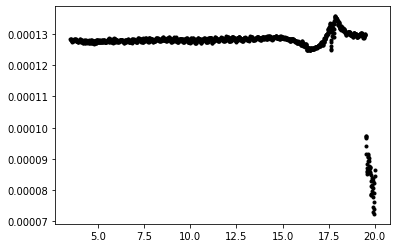

In [335]:
%matplotlib inline
datatable6 = pd.read_csv(r"F:\Maciej\Power_Calibration_11_1\2022-11-03\bias_7mA_try6_new.csv",skiprows=33)
arrX6 = datatable6.X.to_numpy()
arrF6 = datatable6.rf_freq.to_numpy()
plt.plot(arrF6*1e-9,arrX6,'k.')